# Fake job postings: QC, cleaned data, and focused EDA

The order is deliberate: **quality control first, save the cleaned dataset second, explore the full
cleaned dataset third**. EDA is limited to decisions used later: duplicate-aware splitting,
TF-IDF, presence/missingness features, text lengths, and categorical encoding. This is exploratory
model development on the full dataset; it is not a claim that test labels were unseen during design.

In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modules import data_helper as dh
from modules import features as ft
from modules import qc
from modules import report as rp

DATA = "../data/fake_job_postings.csv"
SEEDS = range(5)  # Saved for consistent experiments; this notebook trains no models.
rp.use_style()

## 1. Quality control before EDA

Inspect schema, target values, disguised missing cells, identifying placeholders, exact duplicates,
and uniform columns. Empty cells are not automatically defects: their presence may be a useful
model feature. Rare-but-variable fields are retained.

In [2]:
raw = dh.load_raw(DATA)
content_cols = [c for c in raw if c not in ("job_id", dh.TARGET)]
y = raw[dh.TARGET]
normalised_descriptions = raw["description"].map(
    lambda text: "" if pd.isna(text) else " ".join(str(text).split()).lower()
)
desc_counts = normalised_descriptions.value_counts()
blocks = raw[raw.duplicated(subset=content_cols, keep=False)]
if blocks.empty:
    conflicts = 0
else:
    labels = blocks.groupby(content_cols, dropna=False)[dh.TARGET].nunique()
    conflicts = int((labels > 1).sum())
summary = {
    "shape": [int(raw.shape[0]), int(raw.shape[1])],
    "positive_rate": round(float(y.mean()), 6),
    "n_duplicate_rows": int(raw.duplicated(subset=content_cols, keep="first").sum()),
    "n_rows_shared_description": int(desc_counts[desc_counts > 1].sum()),
    "n_conflicting_duplicate_groups": conflicts,
    "single_value_columns": qc.single_value_columns(raw),
    "class_counts": {0: int((y == 0).sum()), 1: int((y == 1).sum())},
}
pd.Series(summary, name="raw audit").to_frame()

,raw audit
shape,"[17880, 18]"
positive_rate,0.048434
n_duplicate_rows,281
n_rows_shared_description,4552
n_conflicting_duplicate_groups,0
single_value_columns,[]
class_counts,"{0: 17014, 1: 866}"


In [3]:
missing_rows = []
labels = raw["fraudulent"]
for col in dh.TEXT_COLS + ["department"]:
    nan = raw[col].isna()
    junk = ~nan & raw[col].astype(str).str.strip().isin(qc.JUNK_VALUES)
    missing = nan | junk
    missing_rows.append({
        "column": col,
        "NaN": int(nan.sum()),
        "junk": int(junk.sum()),
        "missing % real": round(100 * missing[labels == 0].mean(), 1),
        "missing % fraud": round(100 * missing[labels == 1].mean(), 1),
    })
pd.DataFrame(missing_rows).set_index("column")

,NaN,junk,missing % real,missing % fraud
column,,,,
title,0,0,0.0,0.0
company_profile,3308,0,16.0,67.8
description,1,8,0.0,0.1
requirements,2696,38,15.1,18.1
benefits,7212,30,40.4,42.1
department,11547,0,64.7,61.3


In [4]:
# Original hashes are checked before cleaning replaces them with generic tokens.
raw_text = raw[dh.TEXT_COLS].fillna("").astype(str).agg(" ".join, axis=1)
placeholder_rows = {}
for kind in ("URL", "EMAIL", "PHONE"):
    hashes = raw_text.str.findall(f"#{kind}_[0-9a-fA-F]+")
    placeholder_rows[kind] = {
        "ads": int((hashes.str.len() > 0).sum()),
        "distinct hashes": len({h for values in hashes for h in values}),
    }
pd.DataFrame(placeholder_rows).T

,ads,distinct hashes
URL,5621,1822
EMAIL,1335,392
PHONE,527,159


Only clear defects are repaired. Contact hashes become generic tokens, exact duplicate postings are
removed, and non-key columns with one distinct value (including all-missing) are dropped. A column
with one observed value plus missing entries is retained because its missingness can vary.

For splitting, exact descriptions, company profiles, and original email/phone identities define
related-ad groups. URLs are not grouping keys because shared websites connect large heterogeneous
collections. No fuzzy near-copy clustering or glued-word rewriting is applied.

In [5]:
df = dh.clean(raw)
print(f"rows: {len(raw):,} -> {len(df):,}; removed {len(raw) - len(df):,} exact duplicates")
print("uniform columns removed:", [c for c in raw if c not in df])
print("groups:", df["group"].nunique(), "| largest:", df["group"].value_counts().max())
present_text = [c for c in dh.TEXT_COLS if c in df]
junk_left = sum(
    int(df[c].astype(str).str.strip().isin(qc.JUNK_VALUES).sum()) for c in present_text
)
hashed_left = sum(int(df[c].str.count(qc.PLACEHOLDER).fillna(0).sum()) for c in present_text)
content = df.drop(columns=["job_id", "group", "fraudulent"], errors="ignore")
duplicate_ads = int(content.duplicated().sum())
constants = qc.single_value_columns(df)
assert junk_left == 0, f"{junk_left} junk cells left"
assert hashed_left == 0, f"{hashed_left} hashed placeholders left"
assert duplicate_ads == 0, f"{duplicate_ads} duplicate ads left"
assert not constants, f"single-value columns left: {constants}"
assert "group" in df and df["group"].notna().all(), "rows without a group"

rows: 17,880 -> 17,597; removed 283 exact duplicates
uniform columns removed: []
groups: 4482 | largest: 723


## 2. Save and verify the cleaned dataset

Every later model starts from this file, not from a second implementation of cleaning.

In [6]:
os.makedirs(os.path.dirname(dh.PROCESSED), exist_ok=True)
df.to_csv(dh.PROCESSED, index=False, compression={"method": "gzip", "mtime": 0})
roundtrip = dh.load_processed()
assert roundtrip.equals(df), "saved cleaned data must read back identically"
print("verified", dh.PROCESSED, roundtrip.shape)

verified ../data/processed/emscad_clean.csv.gz (17597, 19)


## 3. Focused EDA on the full cleaned dataset

Class imbalance determines the evaluation focus. The following tables and plots are not a general
column-by-column tour: each one informs a feature or splitting decision used below.

In [7]:
counts = df["fraudulent"].value_counts().sort_index()
pd.DataFrame({
    "ads": counts,
    "share": counts / len(df),
}).rename(index={0: "real", 1: "fraud"})

,ads,share
fraudulent,,
real,16741,0.951355
fraud,856,0.048645


In [8]:
dfe = ft.add_engineered_features(df)
flags = dfe.groupby("fraudulent")[ft.CANDIDATE_BINARY_COLS].mean().T
flags["absolute difference"] = (flags[1] - flags[0]).abs()
flags.sort_values("absolute difference", ascending=False).round(3)

fraudulent,0,1,absolute difference
has_company_profile,0.839,0.322,0.516
has_company_logo,0.818,0.329,0.488
has_questions,0.502,0.291,0.211
has_email,0.068,0.201,0.133
has_salary,0.156,0.258,0.103
has_phone,0.026,0.092,0.066
telecommuting,0.041,0.075,0.034
has_requirements,0.849,0.821,0.027
has_benefits,0.595,0.579,0.015
has_url,0.316,0.310,0.006


saved report figure eda_flags.pdf


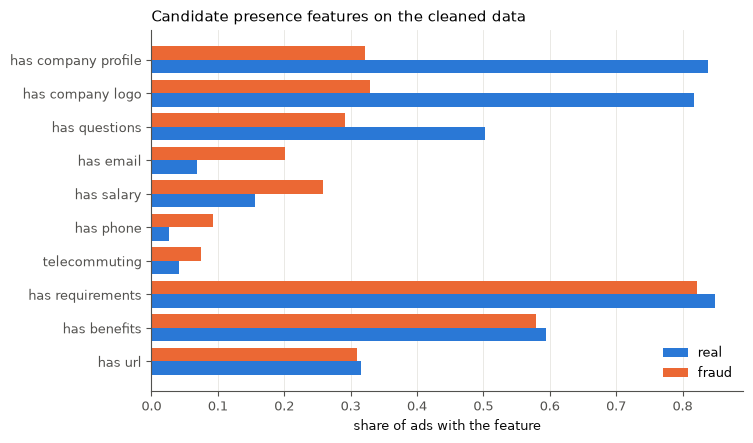

In [9]:
# Presence of each candidate flag by class (report figure).
share = dfe.groupby("fraudulent")[ft.CANDIDATE_BINARY_COLS].mean().T
share = share.loc[(share[1] - share[0]).abs().sort_values().index]
y = np.arange(len(share))
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.barh(y - 0.2, share[0], 0.4, color=rp.BLUE, label="real")
ax.barh(y + 0.2, share[1], 0.4, color=rp.ORANGE, label="fraud")
ax.set_yticks(y, [name.replace("_", " ") for name in share.index])
ax.set_xlabel("share of ads with the feature")
ax.set_title("Candidate presence features on the cleaned data", loc="left")
ax.grid(axis="y", visible=False)
ax.legend()
fig.tight_layout()
rp.save_figure(fig, "eda_flags.pdf")
plt.show()

### Text lengths

Description and requirements lengths are retained as numeric features because their class medians
differ substantially. The other fields remain available in the joined TF-IDF text.

In [10]:
rows = []
for col in dh.TEXT_COLS:
    lengths = df[col].fillna("").astype(str).str.len()
    rows.append({
        "field": col,
        "median real": lengths[df["fraudulent"] == 0].median(),
        "median fraud": lengths[df["fraudulent"] == 1].median(),
    })
pd.DataFrame(rows).set_index("field")

,median real,median fraud
field,,
title,25.0,28.0
company_profile,560.0,0.0
description,1010.0,812.5
requirements,473.0,249.0
benefits,47.0,37.0


saved report figure eda_overview.pdf


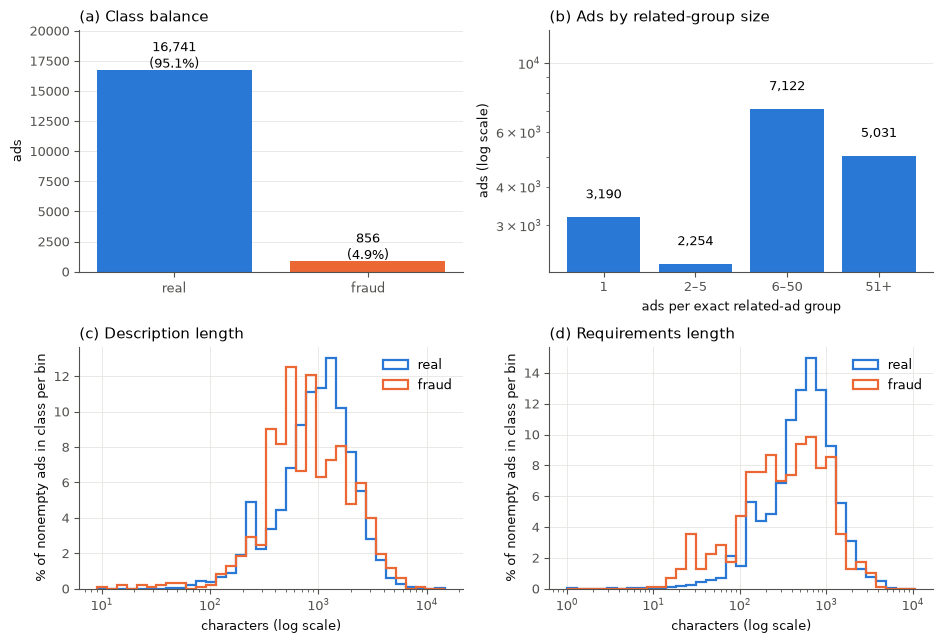

In [11]:
# Class balance, related-group sizes and text-length distributions (report figure).
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.5))
ax = axes[0, 0]
ax.bar(["real", "fraud"], counts.values, color=[rp.BLUE, rp.ORANGE])
for index, value in enumerate(counts.values):
    ax.text(index, value + 200, f"{value:,}\n({value / len(df):.1%})", ha="center")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("(a) Class balance", loc="left")
ax.set_ylabel("ads")
ax.grid(axis="x", visible=False)

sizes = df["group"].map(df["group"].value_counts())
bins = [("1", sizes == 1), ("2–5", sizes.between(2, 5)),
        ("6–50", sizes.between(6, 50)), ("51+", sizes > 50)]
values = [int(mask.sum()) for _, mask in bins]
ax = axes[0, 1]
ax.bar([label for label, _ in bins], values, color=rp.BLUE)
ax.set_yscale("log")
ax.set_ylim(top=max(values) * 1.8)
for index, value in enumerate(values):
    ax.text(index, value * 1.15, f"{value:,}", ha="center")
ax.set_title("(b) Ads by related-group size", loc="left")
ax.set_xlabel("ads per exact related-ad group")
ax.set_ylabel("ads (log scale)")
ax.grid(axis="x", visible=False)

for ax, col, letter in ((axes[1, 0], "description", "c"), (axes[1, 1], "requirements", "d")):
    lengths = df[col].fillna("").astype(str).str.len()
    positive = lengths[lengths > 0]
    edges = np.geomspace(max(1, positive.min()), positive.max(), 36)
    for label, color, name in ((0, rp.BLUE, "real"), (1, rp.ORANGE, "fraud")):
        subset = lengths[(df["fraudulent"] == label) & (lengths > 0)]
        ax.hist(subset, bins=edges, weights=np.full(len(subset), 100 / len(subset)),
                histtype="step", linewidth=1.6, color=color, label=name)
    ax.set_xscale("log")
    ax.set_title(f"({letter}) {col.capitalize()} length", loc="left")
    ax.set_xlabel("characters (log scale)")
    ax.set_ylabel("% of nonempty ads in class per bin")
    ax.legend()
fig.tight_layout()
rp.save_figure(fig, "eda_overview.pdf")
plt.show()

### Candidate categorical features

For each categorical field considered by the model, show the two highest and two lowest fraud rates
among categories with at least 100 ads. This avoids basing decisions on tiny categories while still
retaining those categories in the model matrix. Missing categories remain meaningful.

In [12]:
rows = []
for col in ft.NOMINAL_COLS:
    rates = dfe.groupby(col, dropna=False)["fraudulent"].agg(n="size", fraud_rate="mean")
    rates = rates[rates["n"] >= 100]
    selected = pd.concat([rates.nlargest(2, "fraud_rate"), rates.nsmallest(2, "fraud_rate")])
    for value, row in selected.iterrows():
        display_value = "(missing)" if pd.isna(value) else str(value)
        rows.append({"field": col, "value": display_value, "n": int(row["n"]),
                     "fraud rate": row["fraud_rate"]})
pd.DataFrame(rows).round({"fraud rate": 3})

,field,value,n,fraud rate
0,employment_type,Part-time,772,0.095
1,employment_type,(missing),3426,0.069
2,employment_type,Temporary,237,0.008
3,employment_type,Contract,1514,0.028
4,required_experience,Executive,140,0.071
5,required_experience,Entry level,2637,0.067
6,required_experience,Associate,2267,0.019
7,required_experience,Internship,372,0.027
8,required_education,Certification,165,0.115
9,required_education,High School or equivalent,1989,0.084


saved report figure eda_categories.pdf


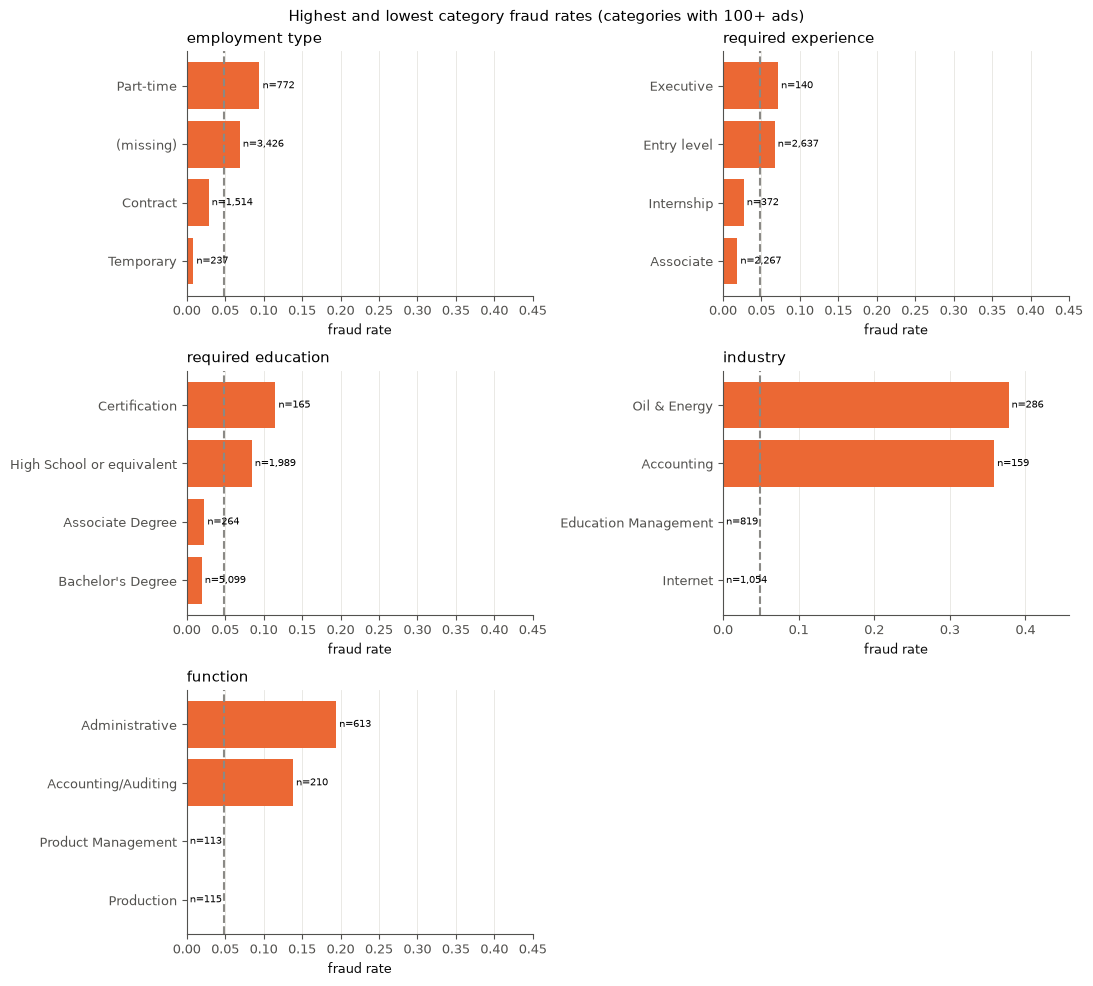

In [13]:
# The same high/low categories as the table above; the dashed line is the overall fraud rate.
category_rates = pd.DataFrame(rows)
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, col in zip(axes.flat, ft.NOMINAL_COLS):
    subset = category_rates[category_rates["field"] == col].sort_values("fraud rate")
    positions = np.arange(len(subset))
    ax.barh(positions, subset["fraud rate"], color=rp.ORANGE)
    ax.axvline(df["fraudulent"].mean(), color=rp.GRAY, linestyle="--")
    ax.set_yticks(positions, [str(value)[:28] for value in subset["value"]])
    ax.set_title(col.replace("_", " "), loc="left")
    ax.set_xlabel("fraud rate")
    for position, (_, row) in zip(positions, subset.iterrows()):
        ax.text(row["fraud rate"] + 0.004, position, f"n={int(row['n']):,}", va="center", fontsize=7)
    ax.set_xlim(0, max(0.45, subset["fraud rate"].max() + 0.08))
    ax.grid(axis="y", visible=False)
axes.flat[-1].set_visible(False)
fig.suptitle("Highest and lowest category fraud rates (categories with 100+ ads)")
fig.tight_layout()
rp.save_figure(fig, "eda_categories.pdf")
plt.show()

### Resulting model features

- Joined title, company profile, description, requirements, and benefits: word unigram/bigram TF-IDF.
- Presence flags with useful class differences: original binary flags, company profile, salary,
  email, and phone.
- Lengths: description and requirements.
- Categorical metadata: employment type, experience, education, industry, and function, one-hot
  encoded with explicit missing values. Rare categories are retained.
- `has_requirements`, `has_benefits`, and `has_url` remain EDA candidates but are not selected;
  their class differences are small.

The preprocessing objects are fitted later, inside each training/CV pipeline. No model transformer
is fitted on the full dataset in this notebook.

In [14]:
print("numeric:", ft.NUMERIC_COLS)
print("binary:", ft.BINARY_COLS)
print("nominal:", ft.NOMINAL_COLS)

numeric: ['desc_len', 'requirements_len']
binary: ['telecommuting', 'has_company_logo', 'has_questions', 'has_company_profile', 'has_salary', 'has_email', 'has_phone']
nominal: ['employment_type', 'required_experience', 'required_education', 'industry', 'function']


## 4. Save balanced grouped splits

Each exact related-ad group stays on one side. The raw email/phone identities are also checked
independently against the split, rather than merely rechecking the generated group labels.

In [15]:
contact_by_id = pd.Series(qc.contact_keys(raw, dh.TEXT_COLS).to_numpy(), index=raw["job_id"])
clean_contacts = dfe["job_id"].map(contact_by_id)
rows = []
for seed in SEEDS:
    splits = dh.make_splits(dfe, seed=seed)
    dh.save_splits(f"splits/seed{seed}.npz", splits, dfe)
    for split, idx in splits.items():
        rows.append({"seed": seed, "split": split, "rows": len(idx),
                     "fraud": int(dfe["fraudulent"].iloc[idx].sum())})
    for other in ("val", "test"):
        assert not set(dfe["group"].iloc[splits["train"]]) & set(dfe["group"].iloc[splits[other]])
    train_contacts = {key for values in clean_contacts.iloc[splits["train"]] for key in values}
    overlap = [key in train_contacts for values in clean_contacts.iloc[splits["test"]] for key in values]
    assert not any(overlap), f"original email/phone identity crossed train/test for seed {seed}"
pd.DataFrame(rows).pivot(index="seed", columns="split", values=["rows", "fraud"])

rows              fraud           
split  test  train   val  test train  val
seed                                     
0      3345  10805  3447   170   535  151
1      3719  10314  3564   181   500  175
2      3438  10401  3758   137   537  182
3      3199  10614  3784   152   542  162
4      3589  10818  3190   187   529  140

## 5. Training-only check of the feature decisions

The EDA above used every cleaned ad. Recomputing the presence-flag class differences and the length
medians on each saved training partition alone shows which feature decisions could have been made
without validation or test rows.

In [16]:
derived_flags = [col for col in ft.CANDIDATE_BINARY_COLS if col not in dh.BIN_COLS]
check_rows = []
for seed in SEEDS:
    train = dfe.iloc[dh.load_splits(f"splits/seed{seed}.npz", dfe)["train"]]
    share = train.groupby("fraudulent")[derived_flags].mean().T
    row = {"seed": seed, **(share[1] - share[0]).abs().round(3).to_dict()}
    for col in ("description", "requirements"):
        lengths = train[col].fillna("").astype(str).str.len()
        nonempty = lengths > 0
        medians = lengths[nonempty].groupby(train.loc[nonempty, "fraudulent"]).median()
        row[f"{col} median real > fraud"] = bool(medians[0] > medians[1])
    check_rows.append(row)
check = pd.DataFrame(check_rows).set_index("seed")
kept = [col for col in derived_flags if col in ft.BINARY_COLS]
excluded = [col for col in derived_flags if col not in ft.BINARY_COLS]
print("kept flags, smallest class difference on any training partition:", check[kept].min().min())
print("excluded flags, largest class difference on any training partition:", check[excluded].max().max())
check

kept flags, smallest class difference on any training partition: 0.066
excluded flags, largest class difference on any training partition: 0.082


,has_company_profile,has_salary,has_email,has_phone,has_requirements,has_benefits,has_url,description median real > fraud,requirements median real > fraud
seed,,,,,,,,,
0,0.469,0.092,0.107,0.080,0.065,0.022,0.027,True,True
1,0.475,0.118,0.147,0.093,0.032,0.010,0.012,True,True
2,0.477,0.066,0.141,0.115,0.022,0.002,0.047,True,True
3,0.460,0.124,0.075,0.094,0.082,0.075,0.017,True,True
4,0.413,0.104,0.093,0.100,0.029,0.012,0.060,True,True


**Next:** notebook 02 fits a dummy, decision tree, logistic regression (text-only versus
text-plus-engineered features), and a PCA-based one-class SVM on all five saved splits. Seed 0
is used for score plots and fitted-model inspection.